# 01. Relaxations of plain JAX code

A global optimizer has to prove that no point in the search box beats the best
point it has found. That proof needs a **lower bound** of $f$ over a box
$B=[\underline{x},\overline{x}]$, valid for every $x\in B$, not just at the
points that were sampled. jaxglobal gets these bounds from the function itself:
it traces the Python function to a jaxpr (JAX's list of primitive operations)
and evaluates that jaxpr in a different arithmetic, where every number is
replaced by an object that bounds it.

This notebook shows the three kinds of bounds jaxglobal combines, on a
one-dimensional function where they can be drawn, and measures how fast they
tighten as the box shrinks. That rate is what makes branch and bound finish.

In [1]:
import pathlib
import sys

ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from jaxglobal import relax
from jaxglobal.problems import gramacy_lee, six_hump_camel

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})

## The test function

The Gramacy–Lee function

$$ f(x) = \frac{\sin(10\pi x)}{2x} + (x-1)^4, \qquad x \in [0.5,\ 2.5], $$

has about twenty local minima and a global minimum $f^* \approx -0.869$ near
$x = 0.549$ [surjanovic2013virtual]. In jaxglobal it is an ordinary function:

In [2]:
import inspect

print(inspect.getsource(gramacy_lee))

def gramacy_lee(x):
    """1-D, many local minima, division by a variable."""
    x = x[0]
    return jnp.sin(10 * jnp.pi * x) / (2 * x) + (x - 1) ** 4



What jaxglobal actually sees is the jaxpr: a straight-line program of
primitives (`sin`, `mul`, `div`, `integer_pow`, ...). Each primitive has a
relaxation rule, and the rules are chained in program order. Nothing about
the function had to be written as an equation.

In [3]:
print(jax.make_jaxpr(gramacy_lee)(jnp.array([1.0])).pretty_print(use_color=False))

{ lambda ; a:f64[1]. let
    b:f64[] = squeeze[dimensions=(0,)] a
    c:f64[] = mul 31.41592653589793:f64[] b
    d:f64[] = sin c
    e:f64[] = mul 2.0:f64[] b
    f:f64[] = div d e
    g:f64[] = sub b 1.0:f64[]
    h:f64[] = integer_pow[y=4] g
    i:f64[] = add f h
  in (i,) }


## Three kinds of bounds

**Interval arithmetic** replaces each intermediate quantity $v$ by an interval
$[\underline v, \overline v]$ that is guaranteed to contain it, e.g.

$$ [a,b]+[c,d]=[a+c,\ b+d],\qquad [a,b]\cdot[c,d] = [\min(ac,ad,bc,bd),\ \max(ac,ad,bc,bd)]. $$

The result is a constant lower bound on the whole box. It is cheap, but it
loses track of correlations: $x - x$ evaluates to $[a-b,\ b-a]$, not $0$.

**McCormick relaxations** [mccormick1976computability] carry, in addition to the
interval, a convex function $f^{cv}(x)$ and a concave function $f^{cc}(x)$ with

$$ f^{cv}(x) \le f(x) \le f^{cc}(x) \qquad \forall x\in B. $$

For a product $w = xy$ with $x\in[x^L,x^U]$, $y\in[y^L,y^U]$ the convex part
is the maximum of two supporting planes,

$$ w^{cv} = \max\big(x^U y + x\,y^U - x^U y^U,\ \ x^L y + x\,y^L - x^L y^L\big), $$

and a univariate function $F$ applied to an inner function $g$ uses the
composition rule

$$ (F\circ g)^{cv}(x) = F^{cv}\big(\operatorname{mid}(g^{cv}(x),\ g^{cc}(x),\ z^{\min})\big), $$

where $F^{cv}$ is the convex envelope of $F$ on the range of $g$ and
$z^{\min}$ is where $F^{cv}$ is smallest [mitsos2009mccormick]. Minimizing the
convex $f^{cv}$ over the box is a convex problem, and its minimum is a lower
bound.

**αBB underestimators** [adjiman1998global, androulakis1995alphabb] subtract a
convex quadratic large enough to remove all negative curvature:

$$ L(x) = f(x) + \sum_i \alpha_i (x_i-\underline x_i)(x_i-\overline x_i), \qquad
   \alpha_i \ge \max\Big(0,\ -\tfrac12 \min_{x\in B}\lambda_{\min}\big(\nabla^2 f(x)\big)\Big). $$

The added term is $\le 0$ on the box and zero at its corners, so $L\le f$.
jaxglobal bounds the Hessian by running the relaxation arithmetic on
`jax.hessian(f)`, which is again just JAX code.

`relax(f)` returns a function `rf(x, lo, hi)` that gives all of this at a point
`x`: the interval (`lo`, `hi`) and the relaxations (`cv`, `cc`).

In [4]:
rf = relax(gramacy_lee)
m = rf(jnp.array([1.0]), jnp.array([0.5]), jnp.array([2.5]))
m

MC(lo=Array(-1., dtype=float64), hi=Array(6.0625, dtype=float64), cv=Array(-0.8, dtype=float64), cc=Array(2.1125, dtype=float64))

## Relaxations tighten when the box is split

On the full domain the bounds are loose: the interval lower bound is far
below $f^*$, and the convex relaxation hugs the function only roughly. Split
the domain into 4 and then 16 boxes, relax $f$ on each, and the relaxations
close in on $f$. This is the whole idea of spatial branch and bound.

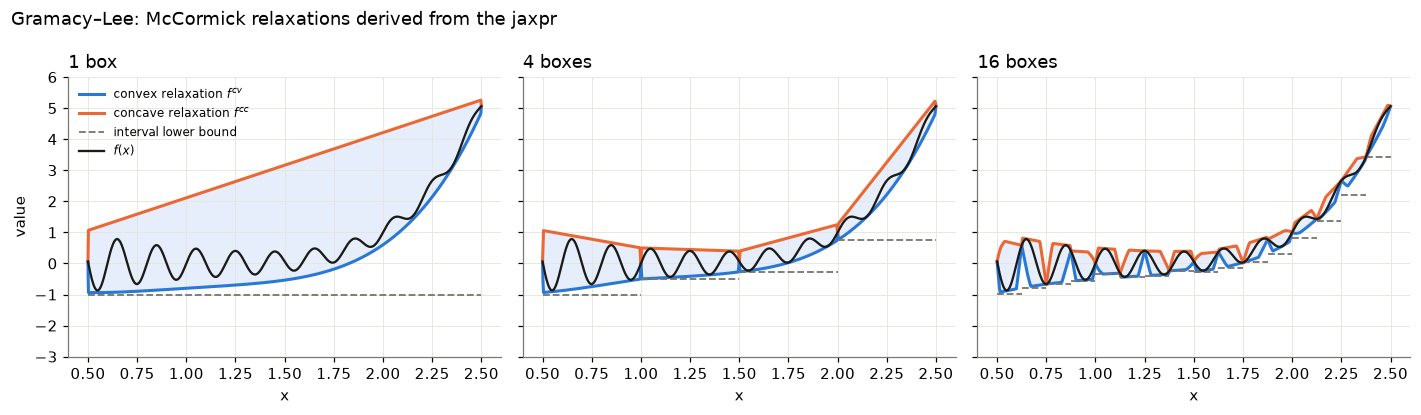

In [5]:
rfv = jax.jit(jax.vmap(relax(gramacy_lee), in_axes=(0, None, None)))
xs = np.linspace(0.5, 2.5, 801)
F = np.asarray(jax.vmap(gramacy_lee)(jnp.asarray(xs[:, None])))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, nbox in zip(axes, [1, 4, 16]):
    edges = np.linspace(0.5, 2.5, nbox + 1)
    for k, (a, b) in enumerate(zip(edges[:-1], edges[1:])):
        sel = (xs >= a) & (xs <= b)
        mm = rfv(jnp.asarray(xs[sel, None]), jnp.array([a]), jnp.array([b]))
        lab = k == 0
        ax.fill_between(xs[sel], np.asarray(mm.cv), np.asarray(mm.cc), color=BLUE, alpha=0.12, lw=0)
        ax.plot(xs[sel], mm.cv, color=BLUE, lw=2, label="convex relaxation $f^{cv}$" if lab else None)
        ax.plot(xs[sel], mm.cc, color=ORANGE, lw=2, label="concave relaxation $f^{cc}$" if lab else None)
        ax.hlines(float(mm.lo[0]), a, b, color=MUTED, lw=1.2, ls="--", label="interval lower bound" if lab else None)
    ax.plot(xs, F, color=INK, lw=1.5, label="$f(x)$")
    ax.set_title(f"{nbox} box{'es' if nbox > 1 else ''}", loc="left")
    ax.set_xlabel("x")
    ax.set_ylim(-3, 6)
axes[0].set_ylabel("value")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Gramacy–Lee: McCormick relaxations derived from the jaxpr", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "relaxations.png", dpi=150)

Two things are visible. First, the convex relaxation $f^{cv}$ (blue) is
always below $f$ (black) and the concave one (orange) always above, as the
theory promises. Second, the interval bound (dashed) is a single constant per
box, while $f^{cv}$ follows the shape of $f$; on small boxes its minimum is
much closer to the true minimum of $f$ on that box.

## How fast do the bounds converge?

Let $w$ be the width of a box $B_w$ around a point $x_0$. A natural measure of
how good an underestimator $u$ is on that box is its largest pointwise
distance from $f$,

$$ \delta(w) = \max_{x\in B_w} \big(f(x) - u(x)\big). $$

For interval arithmetic $u$ is the constant lower end of the interval; for
McCormick it is the convex relaxation $f^{cv}$. Interval arithmetic has
first-order convergence, $\delta = O(w)$, while McCormick relaxations converge
at second order, $\delta = O(w^2)$ [bompadre2012convergence]. The order
matters: when the gap shrinks like $w^2$, far fewer boxes have to be split
before their bounds exceed the incumbent, which keeps the number of nodes in
branch and bound small [kannan2018convergenceorder].

We measure $\delta(w)$ on a dense grid in boxes around $x_0 = 1.3$:

w =  5.0e-01   interval gap = 9.52e-01   McCormick gap = 9.31e-01
w =  1.1e-01   interval gap = 8.01e-01   McCormick gap = 5.14e-01
w =  2.2e-02   interval gap = 2.67e-01   McCormick gap = 9.30e-03
w =  4.7e-03   interval gap = 5.72e-02   McCormick gap = 1.31e-04
w =  1.0e-03   interval gap = 1.21e-02   McCormick gap = 3.07e-06


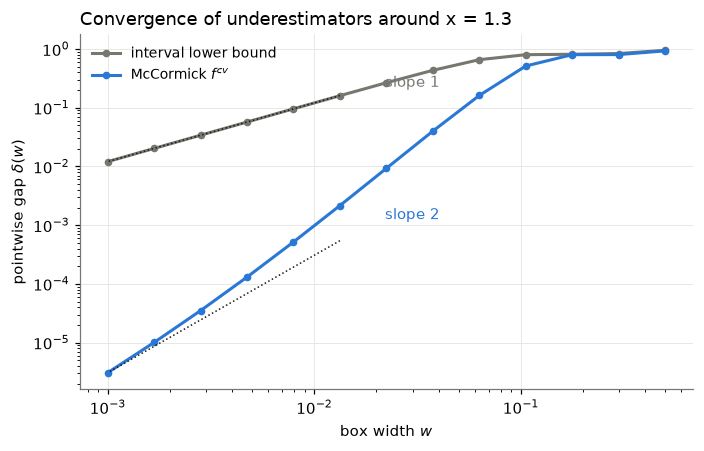

In [6]:
x0 = 1.3
widths = np.geomspace(0.5, 1e-3, 13)
rv = jax.jit(jax.vmap(relax(gramacy_lee), in_axes=(0, None, None)))

rows = []
for w in widths:
    lo, hi = jnp.array([x0 - w / 2]), jnp.array([x0 + w / 2])
    grid = jnp.asarray(np.linspace(x0 - w / 2, x0 + w / 2, 801)[:, None])
    fx = jax.vmap(gramacy_lee)(grid)
    m = rv(grid, lo, hi)
    rows.append((w, float(jnp.max(fx - m.lo)), float(jnp.max(fx - m.cv))))
rows = np.array(rows)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(rows[:, 0], rows[:, 1], "o-", color=MUTED, lw=2, ms=4, label="interval lower bound")
ax.loglog(rows[:, 0], rows[:, 2], "o-", color=BLUE, lw=2, ms=4, label="McCormick $f^{cv}$")
small = widths <= 2e-2  # reference lines through the smallest box
ax.loglog(widths[small], rows[-1, 1] * widths[small] / widths[-1], ":", color=INK, lw=1)
ax.loglog(widths[small], rows[-1, 2] * (widths[small] / widths[-1]) ** 2, ":", color=INK, lw=1)
ax.text(2.2e-2, rows[-1, 1] * 22, "slope 1", color=MUTED, va="center")
ax.text(2.2e-2, rows[-1, 2] * 22**2, "slope 2", color=BLUE, va="center")
ax.set_xlabel("box width $w$")
ax.set_ylabel(r"pointwise gap $\delta(w)$")
ax.set_title(f"Convergence of underestimators around x = {x0}", loc="left")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

for w, di, dm in rows[::3]:
    print(f"w = {w:8.1e}   interval gap = {di:8.2e}   McCormick gap = {dm:8.2e}")

On large boxes the two are similar: both are loose when $w$ spans a whole
oscillation of $\sin(10\pi x)$. Once the box is small enough for $f$ to look
smooth, the interval gap falls in proportion to $w$ and the McCormick gap
like $w^2$, so each factor of 10 in $w$ buys one digit for interval
arithmetic and two for McCormick. At $w=10^{-3}$ the interval gap is still
about $10^{-2}$, four thousand times the McCormick gap.

## The same in two dimensions

In more dimensions the picture is the same: the convex relaxation is a bowl-like
surface under $f$. Here is the six-hump camel function

$$ f(a,b) = \Big(4 - 2.1a^2 + \tfrac{a^4}{3}\Big)a^2 + ab + (-4+4b^2)\,b^2 $$

on the box $[-1, 1]^2$ together with $f^{cv}$. The minimum of the blue
surface is the lower bound for that box.

min f^cv on the box = -5.0000 <= min f = -1.0298: True


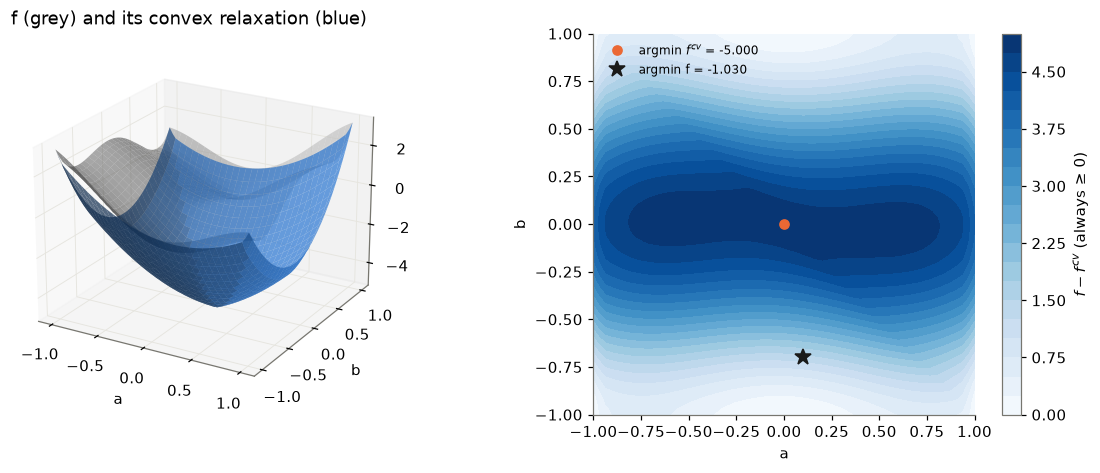

In [7]:
rf2 = jax.jit(jax.vmap(relax(six_hump_camel), in_axes=(0, None, None)))
lo2, hi2 = jnp.array([-1.0, -1.0]), jnp.array([1.0, 1.0])
g = np.linspace(-1, 1, 61)
A, Bm = np.meshgrid(g, g)
P = jnp.asarray(np.c_[A.ravel(), Bm.ravel()])
Fz = np.asarray(jax.vmap(six_hump_camel)(P)).reshape(A.shape)
CV = np.asarray(rf2(P, lo2, hi2).cv).reshape(A.shape)

fig = plt.figure(figsize=(11, 4.3))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(A, Bm, Fz, color="0.75", alpha=0.6, lw=0)
ax.plot_surface(A, Bm, CV, color=BLUE, alpha=0.7, lw=0)
ax.set_xlabel("a"); ax.set_ylabel("b"); ax.set_title("f (grey) and its convex relaxation (blue)", loc="left")
ax.view_init(22, -60)
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contourf(A, Bm, Fz - CV, levels=20, cmap="Blues")
fig.colorbar(cs, ax=ax2, label="$f - f^{cv}$ (always ≥ 0)")
i = np.unravel_index(np.argmin(CV), CV.shape)
ax2.plot(A[i], Bm[i], "o", color=ORANGE, label=f"argmin $f^{{cv}}$ = {CV[i]:.3f}")
j = np.unravel_index(np.argmin(Fz), Fz.shape)
ax2.plot(A[j], Bm[j], "*", color=INK, ms=11, label=f"argmin f = {Fz[j]:.3f}")
ax2.set_xlabel("a"); ax2.set_ylabel("b"); ax2.legend(frameon=False, fontsize=8, loc="upper left")
ax2.set_aspect("equal"); ax2.grid(False)
fig.tight_layout()
print(f"min f^cv on the box = {CV.min():.4f} <= min f = {Fz.min():.4f}:", CV.min() <= Fz.min())

The gap $f - f^{cv}$ is never negative, and it vanishes nowhere on this
fairly large box: the relaxation is valid but not yet tight. Branch and
bound fixes that by splitting the box, as the next notebook shows.

## Summary

* jaxglobal relaxes the jaxpr of a plain Python function, one primitive at a
  time, so any function built from supported primitives gets bounds
  automatically.
* Interval bounds are constant per box and converge at first order; McCormick
  and αBB bounds follow the function's shape and converge at second order.
* The second-order rate is what lets branch and bound certify a global
  minimum with a modest number of boxes.